In this example, we will apply 1CCCV protocol to our battery.
we will charge battery with 1C until battery reach Cut-off voltage (4.2V).
Then we continue with CV charge which means we remain voltage at 4.2 and charge until charge current reach to C/20 (0,25A)

In [280]:
import pybamm
import matplotlib.pyplot as plt

In [281]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%

{'Ambient temperature [K]': 298.15,
 'Bulk solvent concentration [mol.m-3]': 2636.0,
 'Cation transference number': 0.2594,
 'Cell cooling surface area [m2]': 0.00531,
 'Cell thermal expansion coefficient [m.K-1]': 1.1e-06,
 'Cell volume [m3]': 2.42e-05,
 'Contact resistance [Ohm]': 0,
 'Current function [A]': 5.0,
 'EC diffusivity [m2.s-1]': 2e-18,
 'EC initial concentration in electrolyte [mol.m-3]': 4541.0,
 'Electrode height [m]': 0.065,
 'Electrode width [m]': 1.58,
 'Electrolyte conductivity [S.m-1]': <function electrolyte_conductivity_Nyman2008 at 0x000001A4481548B0>,
 'Electrolyte diffusivity [m2.s-1]': <function electrolyte_diffusivity_Nyman2008 at 0x000001A448154820>,
 'Initial SEI thickness [m]': 5e-09,
 'Initial concentration in electrolyte [mol.m-3]': 1000.0,
 'Initial concentration in negative electrode [mol.m-3]': np.float64(872.9150690373064),
 'Initial concentration in positive electrode [mol.m-3]': np.float64(53889.21786785448),
 'Initial temperature [K]': 298.15,
 'L

In [282]:
CCCV_Charging = pybamm.Experiment([
    "Charge at 1C until 4.2V", ## CC Phase will charge the battery at 1C until the voltage reaches 4.2V
    "Hold at 4.2 V until 250 mA", ## CV Phase will hold the voltage at 4.2V until the current drops to C/20 
])

In [283]:
model = pybamm.lithium_ion.DFN() # Create a DFN model

In [284]:
# Create a simulation object with the model, experiment, and parameter values
sim = pybamm.Simulation(model, experiment=CCCV_Charging, parameter_values=parameter_values) 

In [285]:
sim.solve() # Solve the simulation
#sim.plot(["Voltage [V]", "Current [A]"], show_plot=True) # Plot the results in subplots

In [286]:
Solution = sim.solution.cycles
CC_Phase = Solution[0] # Get the first cycle (CC Phase) from the solution object
CV_Phase = Solution[1] # Get the second cycle (CV Phase) from the solution object

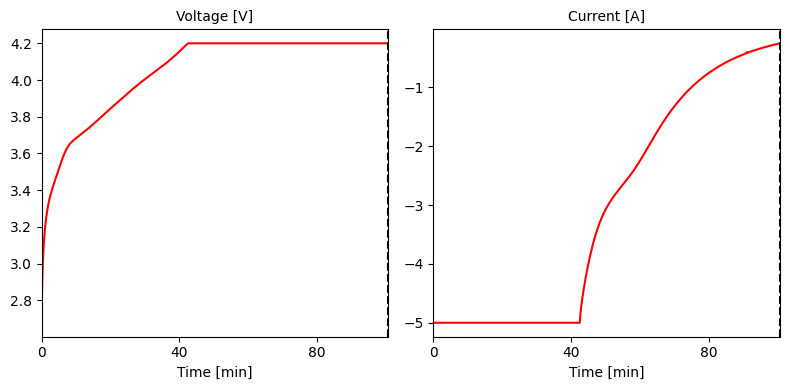

In [287]:
#Let's plot the voltage and current over time for the entire experiment using QuickPlot
qp = pybamm.QuickPlot(sim.solution,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp.plot(qp.max_t) # Plot the voltage and current over time for the entire experiment

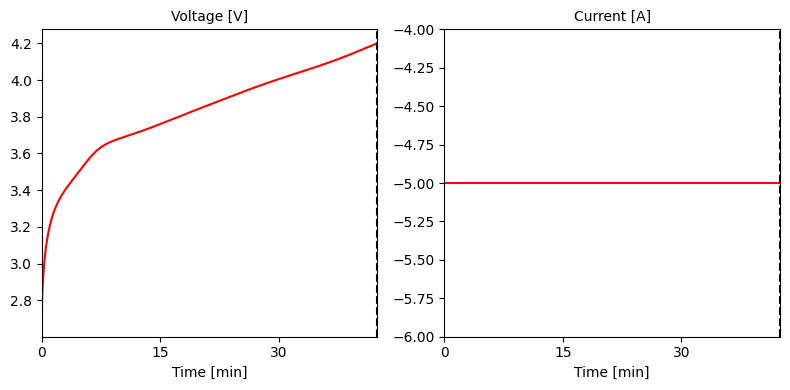

In [288]:
#Let's plot the voltage and current over time for the CC Phase using QuickPlot
qp_CC = pybamm.QuickPlot(CC_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CC.plot(qp_CC.max_t) # Plot the voltage and current over time for CC Phase

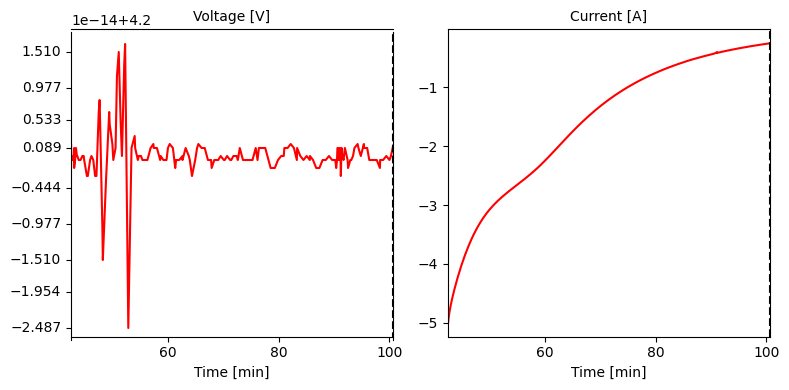

In [289]:
#Let's plot the voltage and current over time for the CV Phase using QuickPlot
qp_CV = pybamm.QuickPlot(CV_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CV.plot(qp_CV.max_t) # Plot the voltage and current over time for CV Phase